# PS7: Flower Classification using YOLOv8 (classification mode)
Dataset: kaggle.com/datasets/imsparsh/flowers-dataset (5 classes, folder labels, no bounding boxes).
Model: yolov8n-cls (ImageNet-pretrained YOLOv8 nano classification head).

In [1]:
import torch

REQUIRE_GPU = True
MIN_FREE_VRAM_GB = 2.0


def _gpu_fail(reason, fix):
    bar = '=' * 66
    raise RuntimeError(f'\n{bar}\nGPU CHECK FAILED - training was NOT started.\n{bar}\nProblem : {reason}\nFix     : {fix}\n{bar}')


if not torch.cuda.is_available():
    if REQUIRE_GPU:
        _gpu_fail('No CUDA GPU is visible to PyTorch (CPU runtime).',
                  'Colab: Runtime > Change runtime type > T4 GPU, then Run all.\n          CPU alternative: set REQUIRE_GPU = False in this cell (slower).')
    print('WARNING: no GPU found; training on CPU because REQUIRE_GPU = False.')
else:
    props = torch.cuda.get_device_properties(0)
    total_gb = props.total_memory / 1024**3
    free_gb = torch.cuda.mem_get_info(0)[0] / 1024**3
    if free_gb < MIN_FREE_VRAM_GB:
        _gpu_fail(f'Only {free_gb:.1f} GB of {total_gb:.1f} GB VRAM is free (need {MIN_FREE_VRAM_GB:.1f} GB).',
                  'Runtime > Restart session, close other GPU notebooks, then Run all again.')
    print(f'GPU OK - {props.name} | {total_gb:.1f} GB total | {free_gb:.1f} GB free')

GPU OK - Tesla T4 | 14.6 GB total | 14.5 GB free


In [2]:
%pip install -q ultralytics kagglehub

import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from ultralytics import YOLO

SEED = 42
DATA_DIR = None
KAGGLE_DATASET = 'imsparsh/flowers-dataset'
VAL_FRACTION = 0.2
EPOCHS = 20
IMG = 224
BATCH = 64
WORKERS = 2
random.seed(SEED)
np.random.seed(SEED)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
if DATA_DIR is None:
    try:
        import kagglehub
        DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as exc:
        print('=' * 66)
        print('DATASET DOWNLOAD FAILED')
        print('Option 1: add a Kaggle API token (Colab Secrets: KAGGLE_API_TOKEN).')
        print('Option 2: set DATA_DIR in the setup cell to a local copy.')
        print('Expected layout: DATA_DIR/train/<class>/*.jpg with 5 class folders.')
        print('=' * 66)
        raise SystemExit('Stopped: dataset not available.') from exc

root = Path(DATA_DIR)
matches = [p.parent for p in root.rglob('daisy') if p.is_dir()]
SRC = matches[0] if matches else root / 'train'
class_names = sorted(d.name for d in SRC.iterdir() if d.is_dir())
files = {c: sorted((SRC / c).glob('*.jpg')) + sorted((SRC / c).glob('*.jpeg')) + sorted((SRC / c).glob('*.png')) for c in class_names}
test_dir = root / 'test'
test_files = sorted(test_dir.glob('*.jpg')) if test_dir.is_dir() else []
print('Source:', SRC)
for c in class_names:
    print(f'{c}: {len(files[c])} images')
print('Total labeled images:', sum(len(v) for v in files.values()))
print('Unlabeled test images:', len(test_files))

Using Colab cache for faster access to the 'flowers-dataset' dataset.
Source: /kaggle/input/flowers-dataset/train
daisy: 501 images
dandelion: 646 images
rose: 497 images
sunflower: 495 images
tulip: 607 images
Total labeled images: 2746
Unlabeled test images: 924


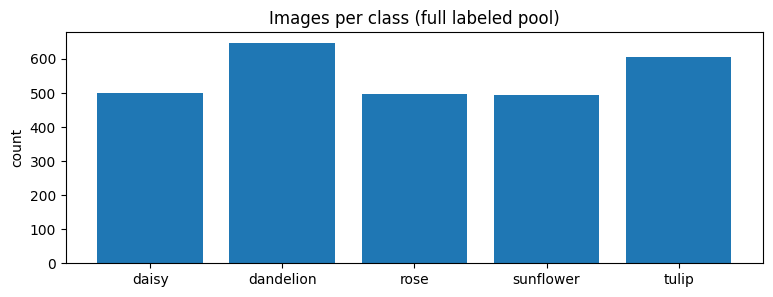

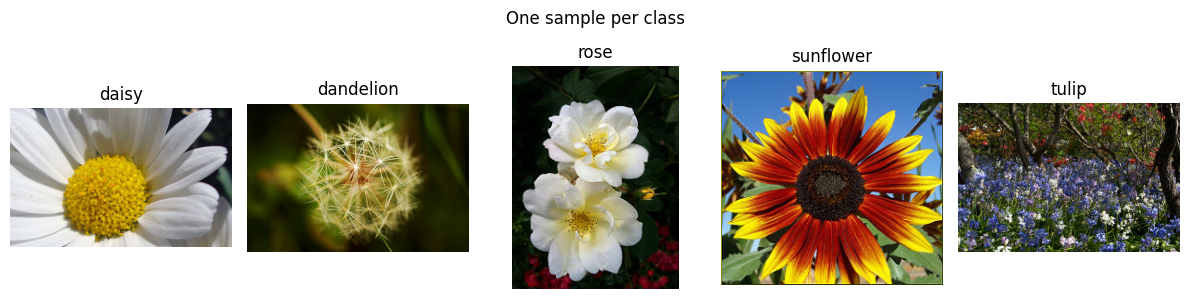

In [4]:
counts = [len(files[c]) for c in class_names]
plt.figure(figsize=(9, 3))
plt.bar(class_names, counts)
plt.title('Images per class (full labeled pool)')
plt.ylabel('count')
plt.show()

plt.figure(figsize=(12, 3))
for i, c in enumerate(class_names):
    img = cv2.imread(str(files[c][0]))
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(c)
    plt.axis('off')
plt.suptitle('One sample per class')
plt.tight_layout()
plt.show()

## Build the train/val split (YOLO classification layout)

In [5]:
OUT = Path('flowers_cls')
for c in class_names:
    imgs = files[c][:]
    random.Random(SEED).shuffle(imgs)
    n_val = max(1, int(len(imgs) * VAL_FRACTION))
    for split, subset in {'train': imgs[n_val:], 'val': imgs[:n_val]}.items():
        dst = OUT / split / c
        dst.mkdir(parents=True, exist_ok=True)
        for f in subset:
            target = dst / f.name
            if not target.exists():
                shutil.copy2(f, target)
        print(f'{c} {split}={len(subset)}')
print('Dataset ready:', OUT.resolve())

daisy train=401
daisy val=100
dandelion train=517
dandelion val=129
rose train=398
rose val=99
sunflower train=396
sunflower val=99
tulip train=486
tulip val=121
Dataset ready: /content/flowers_cls


## Train YOLOv8n-cls

In [6]:
model = YOLO('yolov8n-cls.pt')
model.train(data=str(OUT.resolve()), epochs=EPOCHS, imgsz=IMG, batch=BATCH,
            workers=WORKERS, seed=SEED, patience=10,
            project='runs', name='flower_cls', exist_ok=True)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flowers_cls, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=flower_cls, nbs=64, nms=None, opset=None, optimize=False, optimiz

## Evaluation

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,441,285 parameters, 0 gradients, 3.3 GFLOPs
train: /content/flowers_cls/train... found 2198 images in 5/5 classes ✅ 
val: /content/flowers_cls/val... found 548 images in 5/5 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1735.7±1100.3 MB/s, size: 50.8 KB)
val: Scanning /content/flowers_cls/val... 548 images, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 153.2Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 35/35 15.7it/s 2.2s
                   all      0.958          1
Speed: 0.1ms preprocess, 1.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Top-1 accuracy: 0.9580   Top-5 accuracy: 1.0000


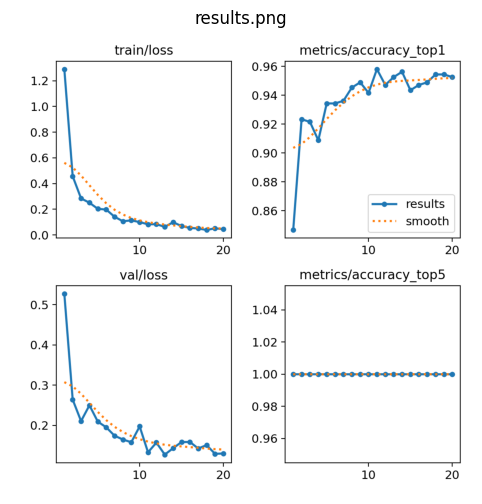

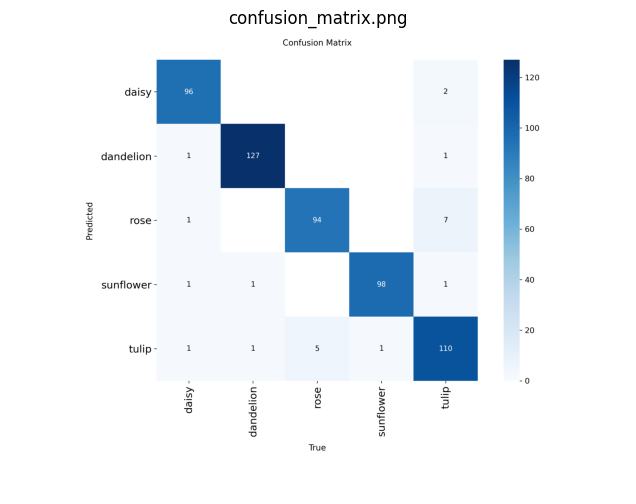

In [7]:
metrics = model.val(data=str(OUT.resolve()), split='val')
print(f'Top-1 accuracy: {metrics.top1:.4f}   Top-5 accuracy: {metrics.top5:.4f}')
for name in ['results.png', 'confusion_matrix.png']:
    p = save_dir / name
    if p.exists():
        plt.figure(figsize=(12, 6))
        plt.imshow(plt.imread(str(p)))
        plt.axis('off')
        plt.title(name)
        plt.show()

              precision    recall  f1-score   support

       daisy     0.9796    0.9600    0.9697       100
   dandelion     0.9845    0.9845    0.9845       129
        rose     0.9216    0.9495    0.9353        99
   sunflower     0.9703    0.9899    0.9800        99
       tulip     0.9322    0.9091    0.9205       121

    accuracy                         0.9580       548
   macro avg     0.9576    0.9586    0.9580       548
weighted avg     0.9581    0.9580    0.9580       548

Macro F1: 0.9580


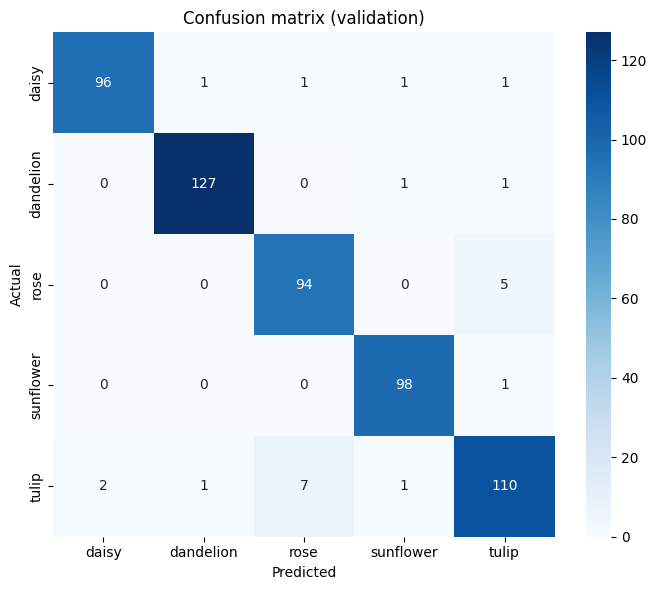

In [8]:
val_paths = sorted((OUT / 'val').rglob('*.jpg'))
y_true = [p.parent.name for p in val_paths]
results = model.predict([str(p) for p in val_paths], imgsz=IMG, verbose=False)
y_pred = [r.names[r.probs.top1] for r in results]
print(classification_report(y_true, y_pred, labels=class_names, digits=4, zero_division=0))
macro_f1 = f1_score(y_true, y_pred, average='macro')
print(f'Macro F1: {macro_f1:.4f}')

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true, y_pred, labels=class_names),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix (validation)')
plt.tight_layout()
plt.show()

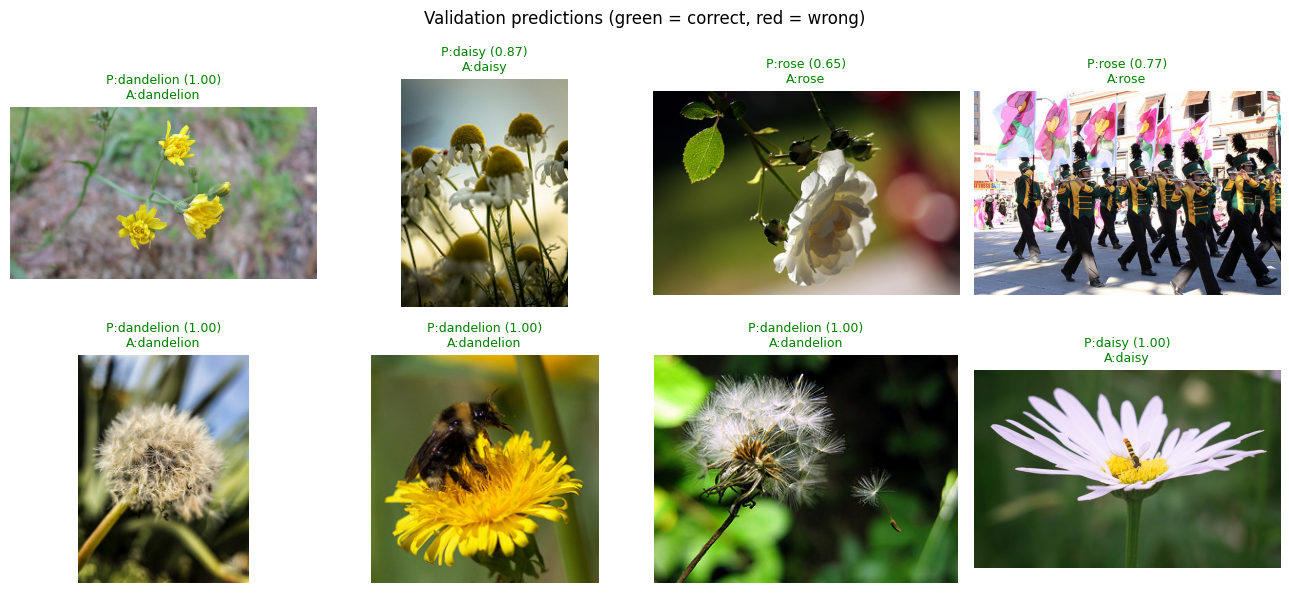

In [9]:
samples = random.Random(SEED).sample(val_paths, 8)
plt.figure(figsize=(13, 6))
for i, p in enumerate(samples):
    r = model.predict(str(p), imgsz=IMG, verbose=False)[0]
    pred = r.names[r.probs.top1]
    conf = float(r.probs.top1conf)
    true = p.parent.name
    plt.subplot(2, 4, i + 1)
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f'P:{pred} ({conf:.2f})\nA:{true}', fontsize=9,
              color='green' if pred == true else 'red')
    plt.axis('off')
plt.suptitle('Validation predictions (green = correct, red = wrong)')
plt.tight_layout()
plt.show()

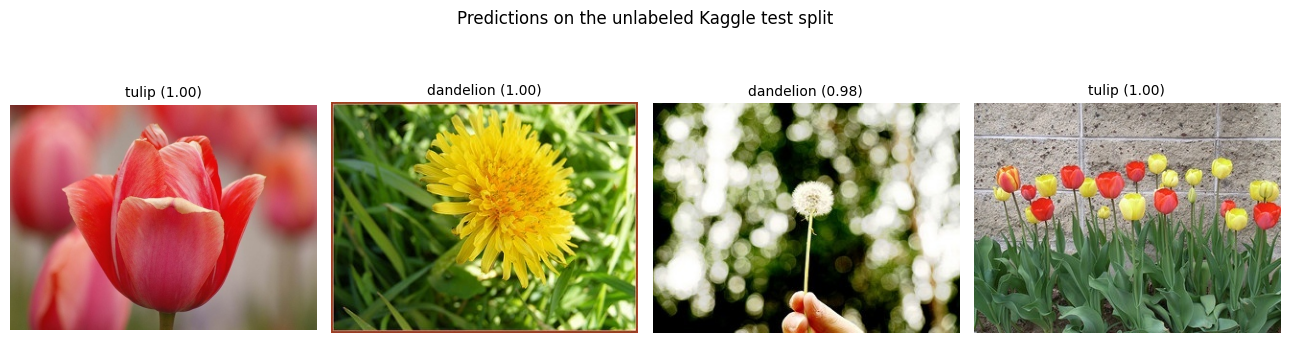

In [10]:
if test_files:
    picks = random.Random(SEED).sample(test_files, 4)
    plt.figure(figsize=(13, 4))
    for i, p in enumerate(picks):
        r = model.predict(str(p), imgsz=IMG, verbose=False)[0]
        plt.subplot(1, 4, i + 1)
        plt.imshow(r.orig_img[..., ::-1])
        plt.title(f'{r.names[r.probs.top1]} ({float(r.probs.top1conf):.2f})', fontsize=10)
        plt.axis('off')
    plt.suptitle('Predictions on the unlabeled Kaggle test split')
    plt.tight_layout()
    plt.show()
else:
    print('No unlabeled test folder found; skipping.')

## Save and single-image inference

In [11]:
out_dir = Path('outputs')
out_dir.mkdir(exist_ok=True)
shutil.copy2(save_dir / 'weights' / 'best.pt', out_dir / 'flowers_yolov8n_cls.pt')
print('Saved:', out_dir / 'flowers_yolov8n_cls.pt')


def classify_image(path, top_k=3):
    r = model.predict(str(path), imgsz=IMG, verbose=False)[0]
    probs = r.probs
    scores = probs.data.cpu().numpy()
    plt.figure(figsize=(5, 5))
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f'{r.names[probs.top1]} ({float(probs.top1conf):.2f})')
    plt.axis('off')
    plt.show()
    return {r.names[i]: round(float(scores[i]), 4) for i in probs.top5[:top_k]}

Saved: outputs/flowers_yolov8n_cls.pt
